# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Naeumi, Gonzales
- _Student No._: 2024-11022
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figures

![Initial spin configurations](12-initial-runs.png)

**Figure 1. Initial spin configurations.** 

![Spin configurations after 10,000 sweeps](12-spins.png)

**Figure 2. Spin configurations after 10,000 sweeps** 

![Magnetization and energy without an external field](12-mE.png)

**Figure 3. Magnetization per spin and total energy versus Monte Carlo sweeps with $B=0$**

![Magnetization and energy with an external field](12-mE-B.png)

**Figure 4. Same as Figure 3 with an external field $B=0.5$.** 

### Report discussion

**Figure 1. Initial spin configurations**

The four starting lattices are random mixtures of up and down spins, so each has a magnetization near zero (between -0.035 and +0.055). Their energies (H = 40, -4, 88, and -16) are close to zero, far above the fully aligned ground state of -800. This is what we expect for a disordered start, where neighboring spins agree and disagree about equally often. The lattices differ only slightly, so any differences later on come from the simulation dynamics rather than from the starting points.

**Figure 2. Spin configurations after 10,000 sweeps**

At T = 1, below T_C, the lattice ends up completely aligned (m = -1, H = -800), which is the lowest possible energy. At T = 3.5, above T_C, the lattice stays a patchwork of small red and blue clusters (m = -0.055, H = -260). Neighboring spins still influence each other, which forms the clusters, but thermal energy keeps breaking up any large-scale order. The contrast shows the phase transition: low temperature favors order, and high temperature favors disorder.

**Figure 3. Magnetization and energy versus sweeps, B = 0**

At T = 1, every run drops quickly to an ordered state with m = +1 or -1 and H = -800. Which sign it picks looks random, because with no field neither direction is favored: runs 1 and 4 end at -1, while runs 2 and 3 end at +1. Runs 2 and 4 also pause for a few hundred sweeps at an intermediate energy near -700, likely because of leftover domains that take time to disappear. At T = 3.5, magnetization fluctuates around zero and energy around -260, with no run settling into order.

**Figure 4. Same as Figure 3 with an external field B = 0.5**

The field favors up spins, so the symmetry between up and down is broken. At T = 1, all four runs quickly reach m ≈ +1 with H ≈ -1000, and the stalls seen in Figure 3 no longer appear. At T = 3.5, magnetization fluctuates around 0.6 and energy around -550. The field now produces a clear positive magnetization, but heat prevents full alignment. This is the key difference from Figure 3, where the high-temperature runs averaged to zero.








**Guide Questions**

*What is the expected initial magnetization?*
- Near zero. Each spin is randomly +1 or -1, so ups and downs roughly cancel. The small leftover is a statistical fluctuation of about 1/N = 0.05, which matches Figure 1 (m between -0.035 and +0.055).

*What is the energy of a completely aligned lattice when J > 0?*
- H = -2JN² = -800. Every spin has two bonds counted once (down and right), each contributing -J, so the total is -J × 2 × 400. The code confirms this (aligned lattice H = -800), and Figures 2 and 3 show the T = 1 runs settling at exactly this value.

*Does the system develop spontaneous magnetization?*
- Yes, but only below T_C. At T = 1 with B = 0, every run ends fully magnetized (|m| = 1) even though it started near zero and no field was applied (Figure 3). Neighboring spins prefer to agree, so one orientation takes over the whole lattice.

*Why can separate simulations produce positive or negative magnetization?*
- Without a field, the energy is the same if every spin is flipped, so up and down are equally good. Random fluctuations early on decide which one wins. The starting sign doesn't decide it: run 4 started slightly positive but ended at -1, while run 2 started positive and ended at +1. In Figure 3, runs 1 and 4 end at -1 and runs 2 and 3 end at +1.

*What determines the preferred spin orientation?*
- With B = 0, nothing in the energy picks a side, so it is chosen by chance. With B > 0, the field picks it. Spins aligned with the field have lower energy, so +1 is preferred.

*How does the external magnetic field affect spin alignment?*
- It adds a bias toward +1. Flipping an up spin down now costs an extra 2B in energy, and flipping a down spin up saves 2B. In Figure 4, all four runs at T = 1 reach m ≈ +1 with H ≈ -1000 (the -800 from bonds plus -0.5 × 400 from the field). The pauses seen in Figure 3 also disappear, since the field guides every run to the same state.

*Why does the system favor one magnetization direction over the other?*
- The Metropolis rule accepts energy-lowering flips more often than energy-raising ones, with probability e^(-ΔH/k_BT). Because aligned-with-field spins have lower energy, the system spends more time in the +1 direction. This is how the symmetry between up and down gets broken.

*Above T_C (Section 5):*
- There is no spontaneous magnetization. At T = 3.5 with B = 0, m fluctuates around zero and H around -260, with only small, short-lived clusters (Figures 2 and 3). Thermal energy beats the coupling that wants spins to align, so no large-scale order survives. With B = 0.5, the lattice becomes only partially magnetized (m ≈ 0.6, H ≈ -550), because heat keeps flipping spins against the field (Figure 4).




### Other comments
- none

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

### Setting Up the Ising Model

Initial lattice: H = 40
Aligned lattice: H = -800


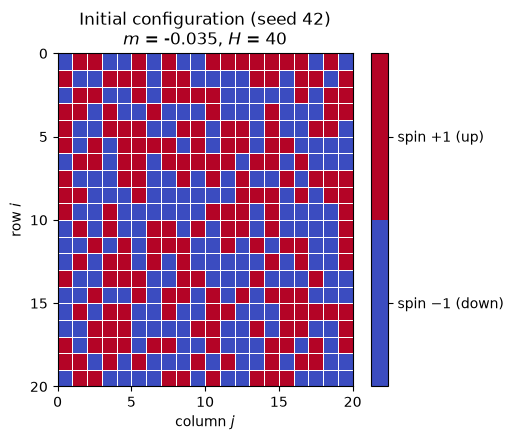

In [9]:
# Parameters
N = 20              
J = 1.0             
T = 1.0             
T_high = 3.5        
Tc = 2.269          
kb = 1.0            
seed = 42           
seeds = [42, 67, 99, 50]   
B = 0.0             
B_field = 0.5       
sweeps = 10000      
sweeps_mE = 2500    


# Building a random lattice
def lattice(N, seed):
    rng = np.random.default_rng(seed) # seeded random generator
    return rng.choice(np.array([-1, 1]), size=(N, N)) # each spin randomly +1 or -1

# Total energy
def ising_ham(S, J, B):
    down = np.roll(S, -1, axis=0) # neighbor below each spin (wraps from last row to first)
    right = np.roll(S, -1, axis=1) # neighbor to the right (wraps from last column to first)
    # Only "down" and "right" are used so each bond is counted exactly once.
    # The last term adds the energy from the external field.
    return -J*np.sum(S*(down + right)) - B*np.sum(S)

# Magnetization per spin
def magnetization(S):
    return np.sum(S)/(N**2)          # average spin: +1 = all up, -1 = all down, 0 = balanced

# Plotting
def plot_spins(S, title, fname=None):
    if np.ndim(S) == 2:                             # a single lattice was given
        S, title = [S], [title]                     # wrap it in a list to treat all cases the same
    plt.figure(figsize=(5.2*len(S), 4.5))           # make the figure wider for more panels
    for k in range(len(S)):
        plt.subplot(1, len(S), k + 1)               # one panel per lattice, side by side
        # Draw each spin as a colored square (2 colors: blue = down, red = up)
        plt.pcolormesh(S[k], cmap=plt.get_cmap("coolwarm", 2), vmin=-1, vmax=1, edgecolors="white", linewidth=0.5)
        plt.gca().invert_yaxis()                    # put row 0 at the top, like a matrix
        plt.xticks(np.arange(0, N + 1, 5))          # tick marks every 5 sites
        plt.yticks(np.arange(0, N + 1, 5))
        cbar = plt.colorbar(ticks=[-0.5, 0.5])      # color legend
        cbar.ax.set_yticklabels(["spin $-1$ (down)", "spin $+1$ (up)"])
        plt.title(title[k])
        plt.xlabel("column $j$")
        plt.ylabel("row $i$")
    plt.tight_layout()
    if fname is not None:                           # save to file only if a filename is given
        plt.savefig(fname, dpi=150)
    plt.show()


# Run: initial state
S0 = lattice(N, seed)                # random starting lattice
H0 = ising_ham(S0, J, B)             # its total energy
print(f"Initial lattice: H = {H0:.0f}")
# Sanity check: all spins aligned gives the lowest possible energy (-2*J*N^2 = -800)
print(f"Aligned lattice: H = {ising_ham(np.ones((N, N)), J, B):.0f}")

# Plot the starting configuration with its magnetization and energy in the title
plot_spins(S0, f"Initial configuration (seed {seed})\n$m$ = {magnetization(S0):+.3f}, $H$ = {H0:.0f}")

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

----
* This code builds a 20×20 grid of randomly assigned up/down spins (a 2D Ising model) and measures its energy, which is the starting point for studying how magnetic order emerges. The energy function uses np.roll to pair each spin with its neighbor below and to its right, which counts every bond exactly once and makes the edges wrap around (periodic boundaries), so no spin is stuck at a “special” border. A fixed random seed makes the starting pattern reproducible, and the all-aligned lattice serves as a sanity check.

### Implementing the Metropolis Algorithm

T = 1.0: final m = -1.000, final H = -800


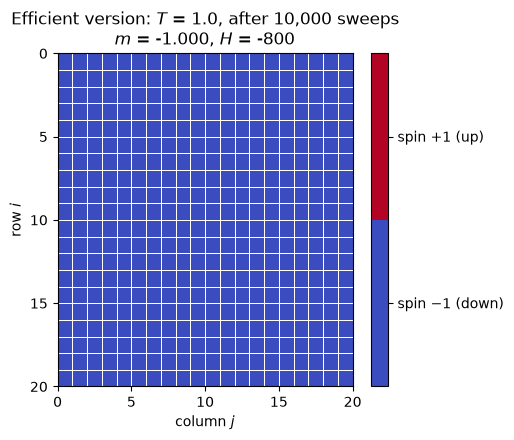

In [10]:
def metropolis_fast(S, T, sweeps, seed, J, B, kb):
    rng = np.random.default_rng(seed) # seeded random generator for reproducibility
    N = S.shape[0] # lattice size


    #Starting values
    E = ising_ham(S, J, B) # starting total energy
    M = int(np.sum(S)) # starting total magnetization
    ms = [M/(N*N)]  # magnetization per spin after each sweep
    Es = [E] # total energy after each sweep

    S = S.tolist()                          
    for sweep in range(sweeps):
    
        # Pre-generate all random numbers for this sweep 
        rows = rng.integers(0, N, N*N).tolist() # random row for each flip attempt
        cols = rng.integers(0, N, N*N).tolist() # random column for each flip attempt
        rs = rng.random(N*N).tolist() # random number in [0, 1) for the accept/reject test

        # One sweep = N*N flip attempts
        for i, j, r in zip(rows, cols, rs):
            s = S[i][j]                     # current spin value (+1 or -1)
            # Sum of the 4 neighbors; % N and negative indexing give periodic boundaries
            nb = S[(i + 1) % N][j] + S[i - 1][j] + S[i][(j + 1) % N] + S[i][j - 1]
            dH = 2*s*(J*nb + B)             # energy change if this spin were flipped (only local terms matter)
        
            # Metropolis rule: always accept if energy drops, otherwise accept with probability e^(-dH/kT)
            if dH <= 0 or r < math.exp(-dH/(kb*T)):
                S[i][j] = -s # flip the spin
                E += dH  # update total energy
                M -= 2*s  # update total magnetization (spin changes by -2s)

        ms.append(M/(N*N)) # record magnetization per spin after this sweep
        Es.append(E) # record energy after this sweep

    return np.array(S), np.array(ms), np.array(Es)  # final lattice, magnetization history, energy history


#Run the simulation at temperature T
S_fast, ms_fast, Es_fast = metropolis_fast(S0, T, sweeps, 10, J, B, kb)
print(f"T = {T}: final m = {ms_fast[-1]:+.3f}, final H = {Es_fast[-1]:.0f}")

# Plot the final lattice with its magnetization and energy in the title
plot_spins(S_fast, f"Efficient version: $T$ = {T}, after {sweeps:,} sweeps\n$m$ = {ms_fast[-1]:+.3f}, $H$ = {Es_fast[-1]:.0f}")

#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

----
* This code simulates the 2D Ising model with the Metropolis algorithm: it picks a random spin, always flips it if that lowers the energy, and otherwise flips it with probability e^(−ΔH/k_BT), so the lattice settles into the right thermal behavior at a given temperature. To make 10,000 sweeps fast, it calculates the energy change from just a spin's four neighbors and updates the running energy and magnetization, instead of recomputing the whole lattice each time. It also pre-generates all random numbers in batches and uses plain Python lists in the inner loop, which are quicker than NumPy for single-spin access.

### Investigating Spontaneous Magnetization

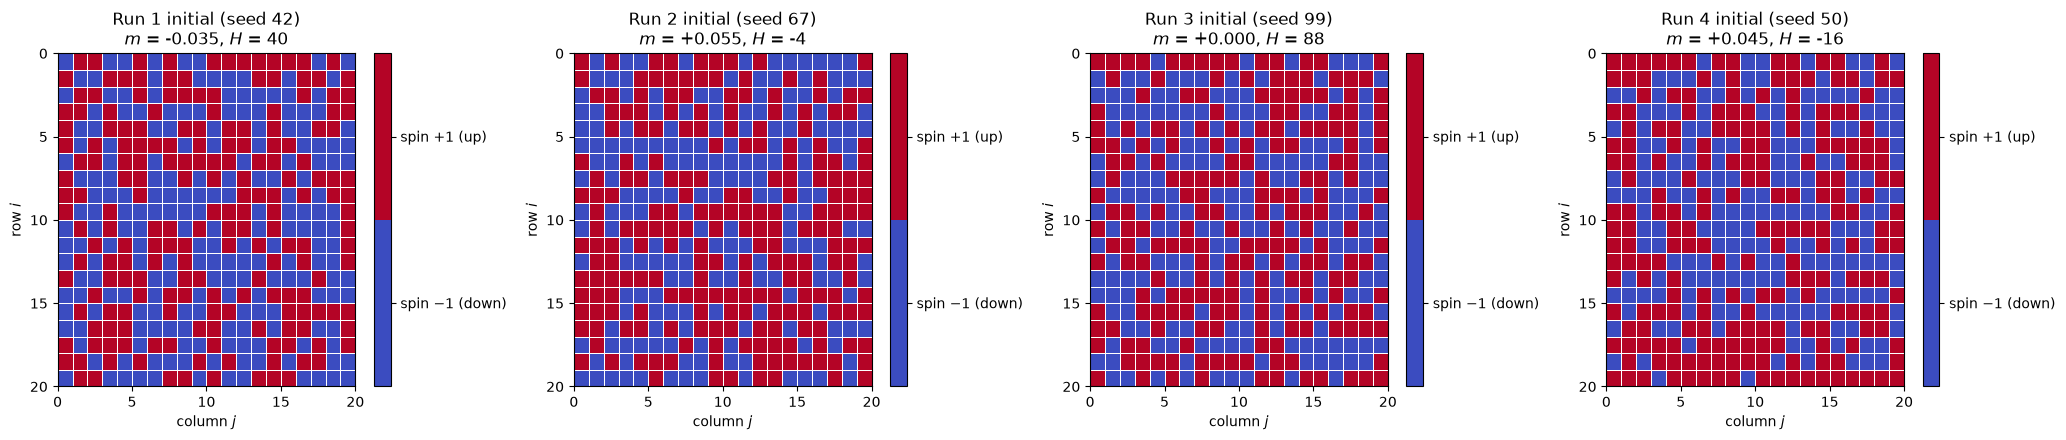

In [11]:
# Show the four starting lattices (one per seed)
S_inits, titles = [], []
for i, s in enumerate(seeds, start=1):
    S_init = lattice(N, s)
    S_inits.append(S_init)
    titles.append(f"Run {i} initial (seed {s})\n"
                  f"$m$ = {magnetization(S_init):+.3f}, $H$ = {ising_ham(S_init, J, B):.0f}")

plot_spins(S_inits, titles, "12-initial-runs.png")

Initial lattice: m = -0.035
T = 1.0, B = 0.0, lattice 42: start m = -0.035, final <m> = -0.999, final <H> = -798.7
T = 1.0, B = 0.0, lattice 67: start m = +0.055, final <m> = +0.999, final <H> = -798.5
T = 1.0, B = 0.0, lattice 99: start m = +0.000, final <m> = +0.999, final <H> = -798.6
T = 1.0, B = 0.0, lattice 50: start m = +0.045, final <m> = -0.999, final <H> = -799.2


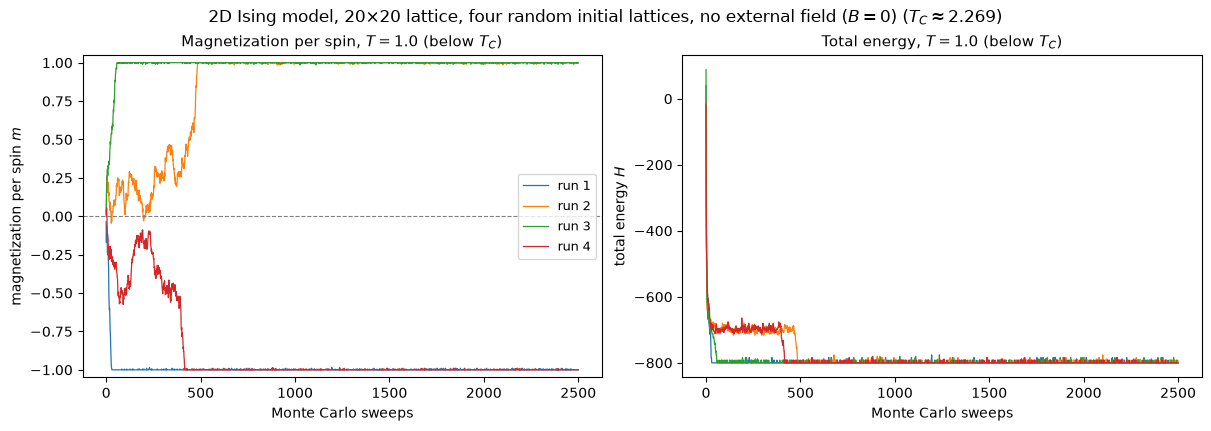

In [12]:

print(f"Initial lattice: m = {magnetization(S0):+.3f}")

# Run one simulation per seed at a given T and B
def run_seeds(T, B):
    runs = []
    for s in seeds:
        S_init = lattice(N, s)

        # s + 100 gives the Monte Carlo moves a different random stream than the lattice itself
        _, ms, Es = metropolis_fast(S_init, T, sweeps_mE, s + 100, J, B, kb)
        runs.append((ms, Es))

        # Averaging the last 500 sweeps gives a stable end value, ignoring the early settling-in
        print(f"T = {T}, B = {B}, lattice {s}: start m = {ms[0]:+.3f}, final <m> = {ms[-500:].mean():+.3f}, final <H> = {Es[-500:].mean():.1f}")
    return runs


# Plot m and H vs. sweeps, one row of panels per temperature
def plot_mE(rows, B, fname=None):
    field = "no external field ($B = 0$)" if B == 0 else f"external field $B = {B}$"
    n = len(rows)
    fig, axes = plt.subplots(n, 2, figsize=(12, 3.9*n + 0.3), layout="constrained", squeeze=False)

    for (runs, T), (ax1, ax2) in zip(rows, axes):
        side = "below" if T < Tc else "above"     # tells the reader which phase to expect
        for i, (ms, Es) in enumerate(runs, start=1):
            ax1.plot(ms, lw=0.9, label=f"run {i}")   # left: magnetization
            ax2.plot(Es, lw=0.9)                     # right: energy

        ax1.axhline(0, color="gray", ls="--", lw=0.8)   # m = 0 means a balanced, disordered lattice
        ax1.set_ylim(-1.05, 1.05)                       # m always lies between -1 and +1
        ax1.set_ylabel("magnetization per spin $m$")
        ax2.set_ylabel("total energy $H$")
        ax1.set_title(f"Magnetization per spin, $T = {T}$ ({side} $T_C$)", fontsize=11)
        ax2.set_title(f"Total energy, $T = {T}$ ({side} $T_C$)", fontsize=11)

    for ax in axes[-1]:
        ax.set_xlabel("Monte Carlo sweeps")             # x-label only on the bottom row

    fig.suptitle(f"2D Ising model, {N}$\\times${N} lattice, four random initial lattices, {field} ($T_C \\approx {Tc}$)")
    axes[0, 0].legend(loc="best", fontsize=9)           # one legend is enough, since colors match across panels
    if fname is not None:
        fig.savefig(fname, dpi=150)
    plt.show()

runs = run_seeds(T, B)
plot_mE([(runs, T)], B)


#### Problem 3 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

----
* This code tracks how the Ising lattice evolves by running the Metropolis simulation from four different random starting lattices (different seeds) and recording the magnetization per spin and total energy after every sweep. Using several seeds shows whether the result depends on where the system starts or is a genuine feature of the physics, and the averages over the last 500 sweeps give a stable end value that ignores the early settling-in period. The plotting function puts magnetization and energy side by side against sweeps to show whether the spins are ordering (low T) or staying disordered (high T).

### Introducing an External Magnetic Field

T = 1.0, B = 0.5, lattice 42: start m = -0.035, final <m> = +1.000, final <H> = -999.7
T = 1.0, B = 0.5, lattice 67: start m = +0.055, final <m> = +1.000, final <H> = -999.4
T = 1.0, B = 0.5, lattice 99: start m = +0.000, final <m> = +1.000, final <H> = -999.5
T = 1.0, B = 0.5, lattice 50: start m = +0.045, final <m> = +1.000, final <H> = -999.5


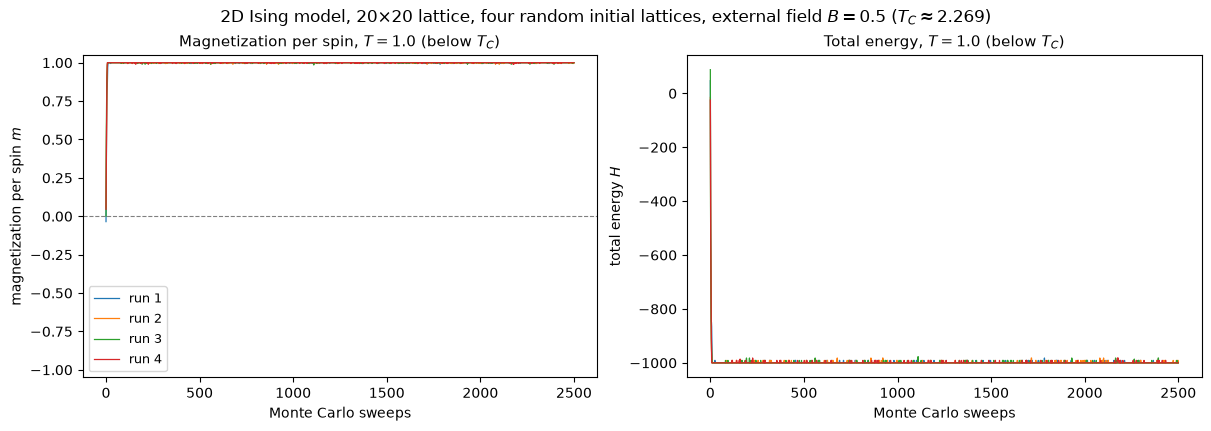

In [13]:
runs_B = run_seeds(T, B_field)
plot_mE([(runs_B, T)], B_field)

#### Problem 4 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

----
* This code reruns the same simulation with an external field of B = 0.5. It didn’t need a new algorithm because the field term was already built into the energy and the Metropolis flip rule (ΔH = 2s(J·neighbors + B)), so changing B is enough. The field gives every spin an extra push toward +1, so all four random starting lattices should drift to a positive magnetization instead of settling into either direction as they would with B = 0, and the plots show this.

### Critical Temperature

T = 3.5: final m = -0.055, final H = -260


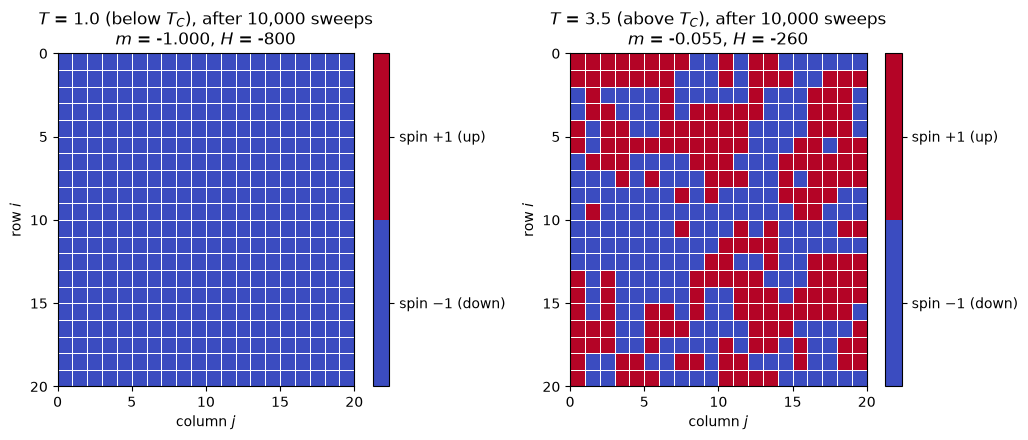

T = 3.5, B = 0.0, lattice 42: start m = -0.035, final <m> = +0.001, final <H> = -264.9
T = 3.5, B = 0.0, lattice 67: start m = +0.055, final <m> = -0.008, final <H> = -262.3
T = 3.5, B = 0.0, lattice 99: start m = +0.000, final <m> = +0.005, final <H> = -264.7
T = 3.5, B = 0.0, lattice 50: start m = +0.045, final <m> = -0.008, final <H> = -262.4


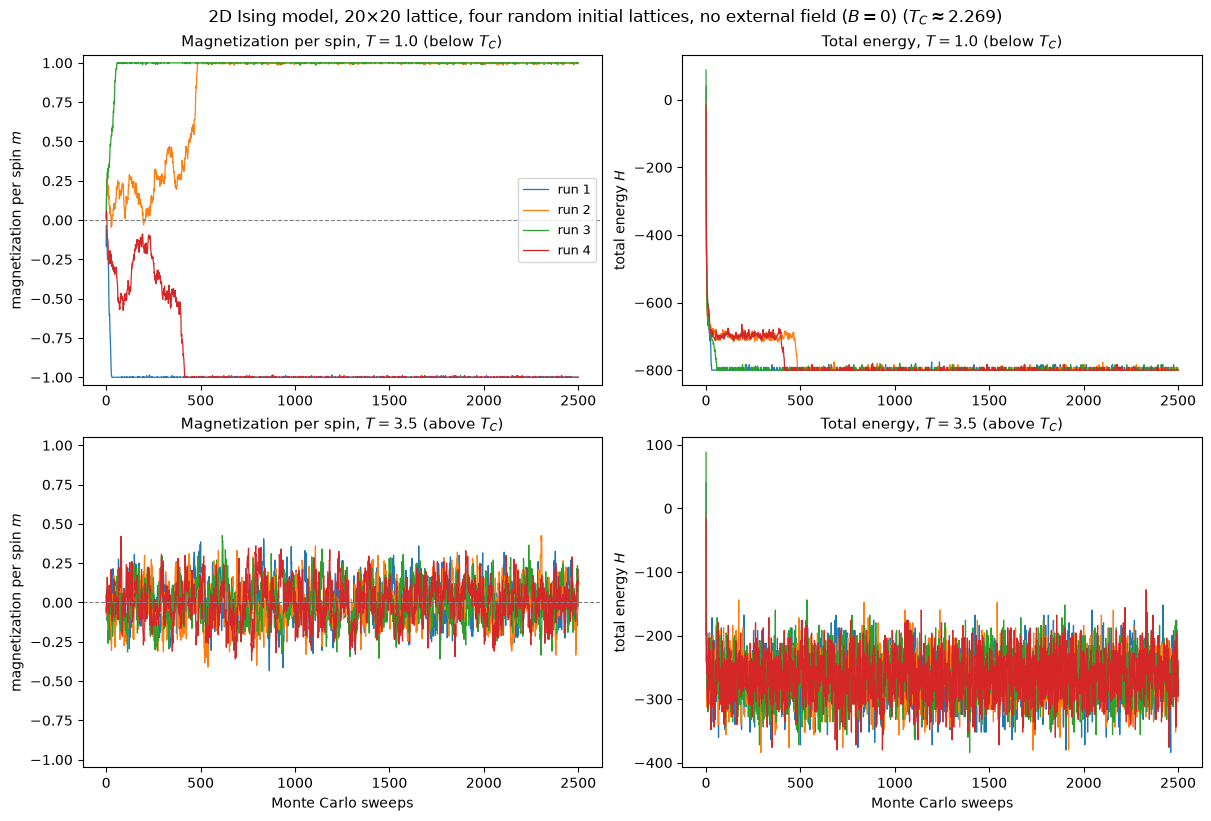

T = 3.5, B = 0.5, lattice 42: start m = -0.035, final <m> = +0.601, final <H> = -532.8
T = 3.5, B = 0.5, lattice 67: start m = +0.055, final <m> = +0.606, final <H> = -534.4
T = 3.5, B = 0.5, lattice 99: start m = +0.000, final <m> = +0.598, final <H> = -529.8
T = 3.5, B = 0.5, lattice 50: start m = +0.045, final <m> = +0.602, final <H> = -532.9


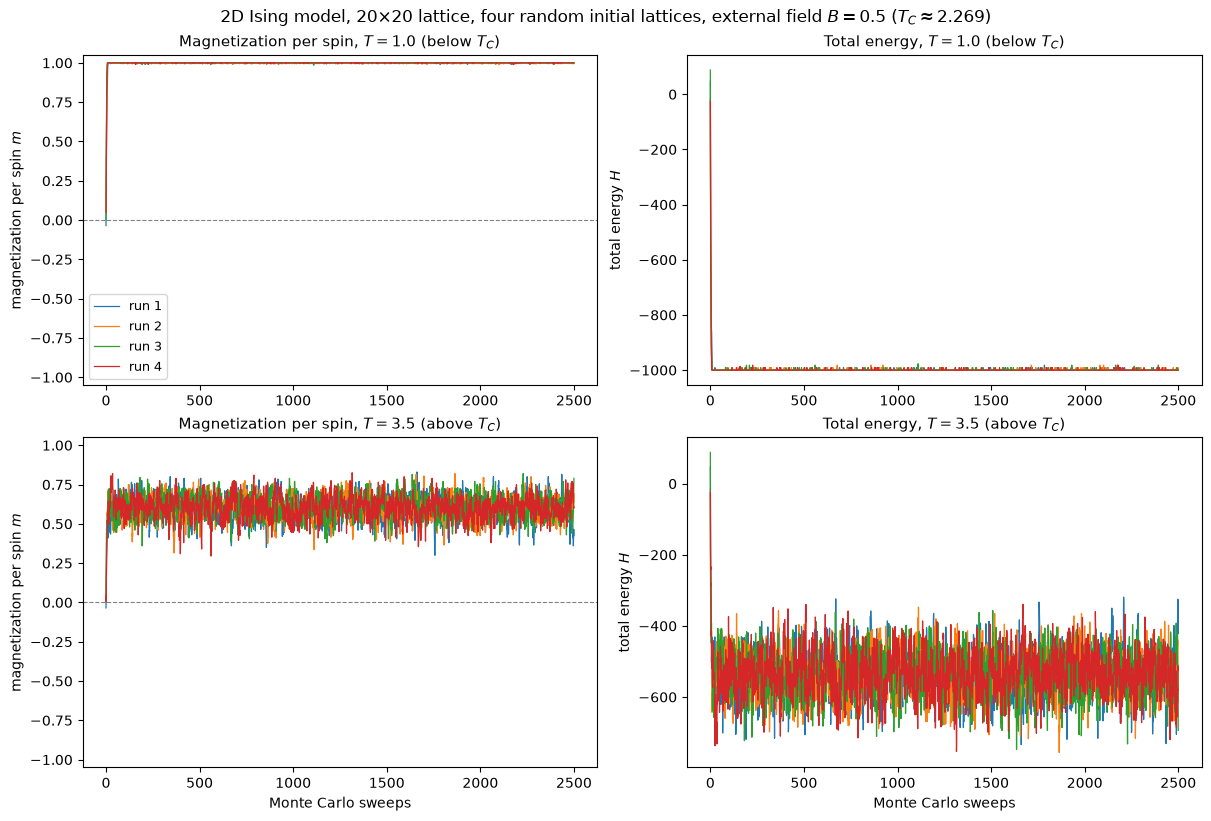

In [16]:
S_final, ms, Es = metropolis_fast(S0, T, sweeps, 10, J, B, kb)

# Single long run above T_c, to compare with the T = 1 run 
S_final_high, ms_high, Es_high = metropolis_fast(S0, T_high, sweeps, 10, J, B, kb)
print(f"T = {T_high}: final m = {ms_high[-1]:+.3f}, final H = {Es_high[-1]:.0f}")

# Side-by-side final lattices: low T vs. high T 
titles = []
for S_end, T_run in zip((S_final, S_final_high), (T, T_high)):
    side = "below" if T_run < Tc else "above"      # label which phase each run is in
    titles.append(f"$T$ = {T_run} ({side} $T_C$), after {sweeps:,} sweeps\n"
                  f"$m$ = {magnetization(S_end):+.3f}, $H$ = {ising_ham(S_end, J, B):.0f}")
plot_spins([S_final, S_final_high], titles, "12-spins.png")

# m and H over time, no field: low T (top row) vs. high T (bottom row)
runs_high = run_seeds(T_high, B)
plot_mE([(runs, T), (runs_high, T_high)], B, "12-mE.png")

# Same comparison with the external field switched on
runs_B_high = run_seeds(T_high, B_field)
plot_mE([(runs_B, T), (runs_B_high, T_high)], B_field, "12-mE-B.png")

#### Problem 5 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

----
* This code repeats the earlier experiments at T = 3.5, above the critical temperature of about 2.269, so it can be compared directly with the T = 1 results. It reuses the same simulation and plotting functions and only changes the temperature, which keeps the comparison fair, and it stacks the low-T and high-T results in shared figures so the contrast is visible at a glance. 

# Alternative for Problem 1

T = 1.0: final m = -1.000, final H = -800


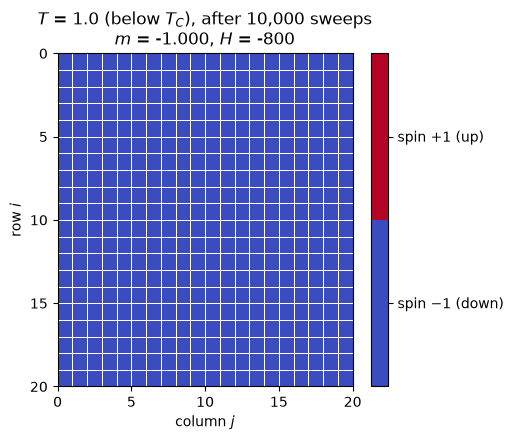

In [18]:
def metropolis_alg(S, T, sweeps, seed, J, B, kb):
    rng = np.random.default_rng(seed)
    S = S.copy()                            # work on a copy so the original lattice is untouched
    N = S.shape[0]

    E = ising_ham(S, J, B)                  # starting energy
    ms = [np.sum(S)/(N*N)]                  # magnetization per spin after each sweep
    Es = [E]                                # total energy after each sweep

    for sweep in range(sweeps):
        # Pre-generate the random choices for one sweep (N*N flip attempts)
        rows = rng.integers(0, N, N*N)
        cols = rng.integers(0, N, N*N)
        rs = rng.random(N*N)                # used for the accept/reject test

        for i, j, r in zip(rows, cols, rs):
            S[i, j] = -S[i, j]                  # tentatively flip the spin
            E_new = ising_ham(S, J, B)          # recompute the full energy (simple but slow)

            # Metropolis rule: keep the flip if energy drops, otherwise keep it with probability e^(-dH/kT)
            if E_new <= E or r < math.exp(-(E_new - E)/(kb*T)):
                E = E_new                       # accepted: store the new energy
            else:
                S[i, j] = -S[i, j]              # rejected: undo the flip

        # Record the state after each full sweep
        ms.append(np.sum(S)/(N*N))
        Es.append(E)

    return S, np.array(ms), np.array(Es)



# Run the slow, straightforward version at temperature T 
S_final, ms, Es = metropolis_alg(S0, T, sweeps, 10, J, B, kb)
print(f"T = {T}: final m = {ms[-1]:+.3f}, final H = {Es[-1]:.0f}")

plot_spins(S_final, f"$T$ = {T} (below $T_C$), after {sweeps:,} sweeps\n$m$ = {ms[-1]:+.3f}, $H$ = {Es[-1]:.0f}")